<a href="https://colab.research.google.com/github/iarapineda/Ciencia-y-anal-tica-de-datos-Sep2026/blob/main/Actividad4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Iara Pérez Pineda
*   MATRÍCULA: A01705855

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [3]:
loan_df = pd.read_csv('/content/personal_loan.csv')
loan_df.set_index('ID', inplace=True)
display(loan_df.head())
loan_df.info()

num = loan_df.select_dtypes(include='number').shape[1]
texto = loan_df.select_dtypes(include='object').shape[1]

print("Columnas numéricas:", num)
print("Columnas de texto:", texto)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB
Columnas numéricas: 8
Columnas de texto: 5


Se importó el conjunto de datos con 5,037 registros y se estableció la columna ID como índice. Mediante info() se identificaron 13 columnas: 8 numéricas y 5 de tipo texto (object). Algunas variables binarias están representadas como texto, por lo que será necesario unificar sus formatos durante la limpieza.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [4]:
display(loan_df.describe())

display(loan_df[loan_df["Age"] > 100])


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [5]:

total_inicial = len(loan_df)

loan_df = loan_df[
    (loan_df["Age"] <= 100) &
    (loan_df["Experience"] >= 0) &
    (loan_df["Family"] >= 1) &
    (loan_df["Education"].isin([1, 2, 3])) &
    (loan_df["ZIP Code"].between(10000, 99999))
].copy()

eliminados = total_inicial - len(loan_df)

print("Registros eliminados:", eliminados)
print("Porcentaje eliminado:", round(eliminados / total_inicial * 100, 2), "%")
print("Registros restantes:", len(loan_df))


Registros eliminados: 60
Porcentaje eliminado: 1.19 %
Registros restantes: 4977


Se revisaron las estadísticas descriptivas de las variables numéricas y se identificaron registros inconsistentes: tres edades superiores a 100 años (123, 130 y 144), 53 valores negativos de experiencia laboral, dos valores negativos en Family, un nivel educativo de 7.3 fuera de las categorías permitidas (1 2 y 3) y un código postal de cuatro dígitos (9307), cuya validez no pudo confirmarse.

Se eliminaron estos registros por contener valores no plausibles o incompatibles con las definiciones del dataset. En total, se eliminaron 60 registros (1.19%) de los 5,037 originales, conservando 4,977 para el análisis posterior.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [6]:
texto_cols = loan_df.select_dtypes(include="object").columns

display(loan_df[texto_cols].describe())

for col in texto_cols:
    print(f"\n{col}")
    print(loan_df[col].value_counts())


,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628



Personal Loan
Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64

Securities Account
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64

CD Account
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64

Online
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64

CreditCard
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64


In [7]:
for col in texto_cols:
    loan_df[col] = loan_df[col].map({
        "Yes": 1, "No": 0,
        "1": 1, "0": 0
    })

display(loan_df[texto_cols].apply(pd.Series.value_counts))


,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,4492,4458,4674,2002,3513
1,485,519,303,2975,1464


Se analizaron las cinco variables de texto y sus frecuencias, se identificó que las variables binarias utilizaban diferentes representaciones para los mismos valores: 0, 1, Yes y No.

Para mantener la consistencia con el diccionario de datos, se unificaron los valores utilizando 1 para respuestas afirmativas y 0 para negativas. Después de la conversión, las cinco variables quedaron representadas correctamente mediante dos categorías numéricas, sin modificar la cantidad de registros.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [8]:
duplicados = loan_df.duplicated().sum()
print("Registros duplicados:", duplicados)

loan_df = loan_df.drop_duplicates().reset_index(drop=True)

print("Registros restantes:", len(loan_df))
print("Índice:", loan_df.index)


Registros duplicados: 36
Registros restantes: 4941
Índice: RangeIndex(start=0, stop=4941, step=1)


Son 36 registros duplicados, los cuales fueron eliminados para evitar observaciones repetidas en el análisis. Posteriormente, se reinició el índice para mantener una secuencia continua.

El dataset quedó conformado por 4,941 registros, después de eliminar 60 registros inválidos y 36 duplicados.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [9]:
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype("object")

loan_df["Education"] = pd.Categorical(
    loan_df["Education"],
    categories=[1, 2, 3],
    ordered=True
)

bin_cols = ["Personal Loan", "Securities Account",
            "CD Account", "Online", "CreditCard"]

loan_df[bin_cols] = loan_df[bin_cols].astype("category")

num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

loan_df.info()
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4941 entries, 0 to 4940
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4941 non-null   int64   
 1   Experience          4941 non-null   int64   
 2   Income              4941 non-null   int64   
 3   ZIP Code            4941 non-null   object  
 4   Family              4941 non-null   int64   
 5   CCAvg               4941 non-null   float64 
 6   Education           4941 non-null   category
 7   Mortgage            4941 non-null   int64   
 8   Personal Loan       4941 non-null   category
 9   Securities Account  4941 non-null   category
 10  CD Account          4941 non-null   category
 11  Online              4941 non-null   category
 12  CreditCard          4941 non-null   category
dtypes: category(6), float64(1), int64(5), object(1)
memory usage: 300.0+ KB
Numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mor

Se revisaron la naturaleza estadística de las variables y se realizaron las conversiones correspondientes. ZIP Code se clasificó como nominal, Education como categórica ordinal con niveles ordenados del 1 al 3, y las cinco variables binarias como categóricas.

Finalmente, se crearon las listas `num_cols` y `cat_cols`, identificando **6 variables numéricas y 7 categóricas** para facilitar el análisis exploratorio posterior.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [10]:
estadisticas = loan_df[num_cols].describe().T

estadisticas["Asimetría"] = loan_df[num_cols].skew()
estadisticas["Curtosis"] = loan_df[num_cols].kurt()

display(estadisticas.round(3))


,count,mean,std,min,25%,50%,75%,max,Asimetría,Curtosis
Age,4941.0,45.560,11.316,24.0,36.0,46.0,55.0,67.0,-0.023,-1.162
Experience,4941.0,20.335,11.308,0.0,11.0,20.0,30.0,43.0,-0.015,-1.135
Income,4941.0,73.827,46.107,8.0,39.0,64.0,98.0,224.0,0.842,-0.046
Family,4941.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.159,-1.404
CCAvg,4941.0,1.936,1.748,0.0,0.7,1.5,2.6,10.0,1.595,2.636
Mortgage,4941.0,56.664,101.875,0.0,0.0,0.0,101.0,635.0,2.104,4.760


Se calculó las estadísticas descriptivas de las 6 variables numéricas, incorporando asimetría y curtosis.

- **Age:** presenta una distribución aproximadamente simétrica (−0.023) y platicúrtica (−1.162), con colas menos pesadas que una distribución normal.
- **Income:** muestra una asimetría positiva moderada (0.842), indicando una mayor extensión hacia ingresos altos. Su curtosis (−0.046) es cercana a cero, por lo que se clasifica como aproximadamente mesocúrtica.
- **Mortgage:** presenta una asimetría positiva pronunciada (2.104) y una distribución leptocúrtica (4.760), lo que indica una cola extendida hacia valores elevados y mayor presencia de valores extremos.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

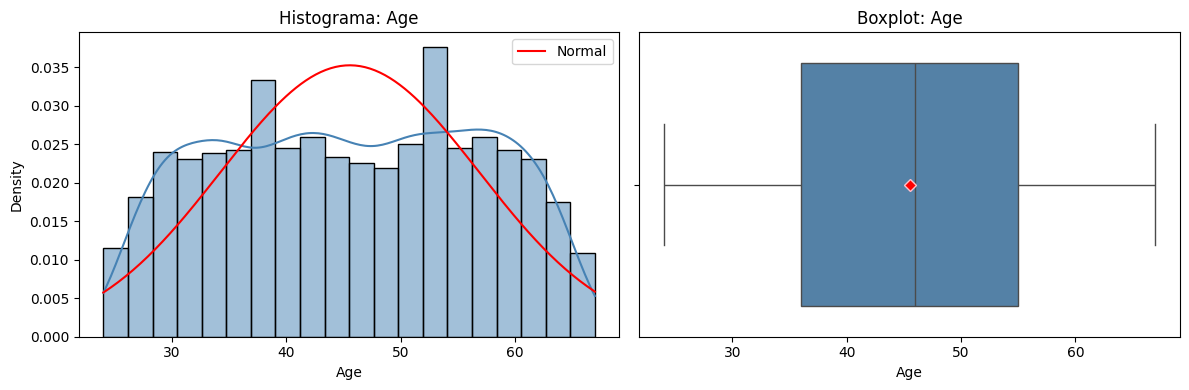

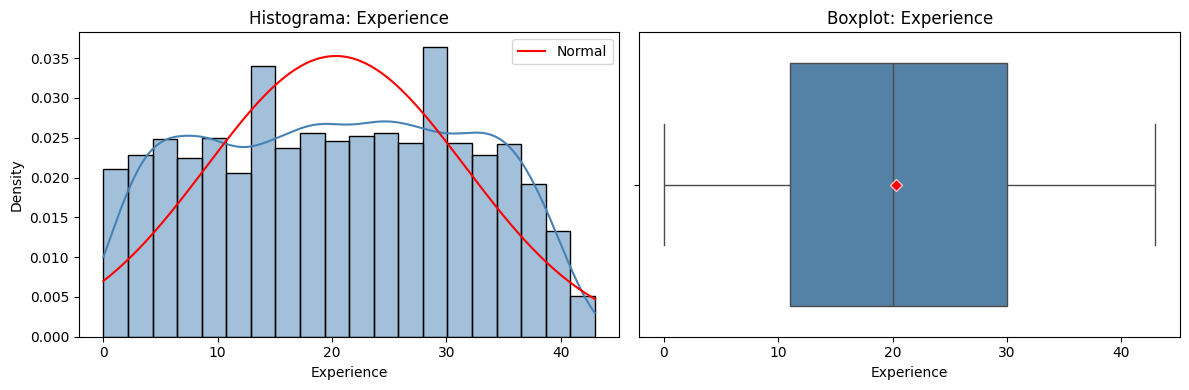

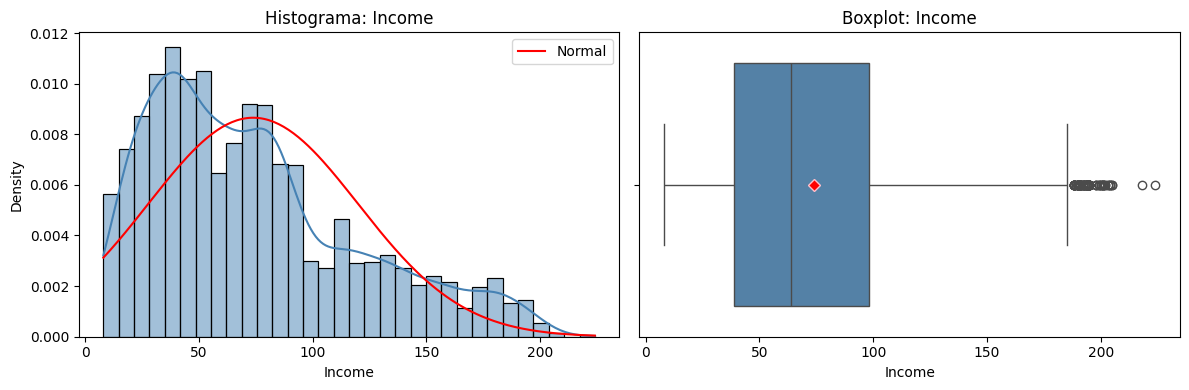

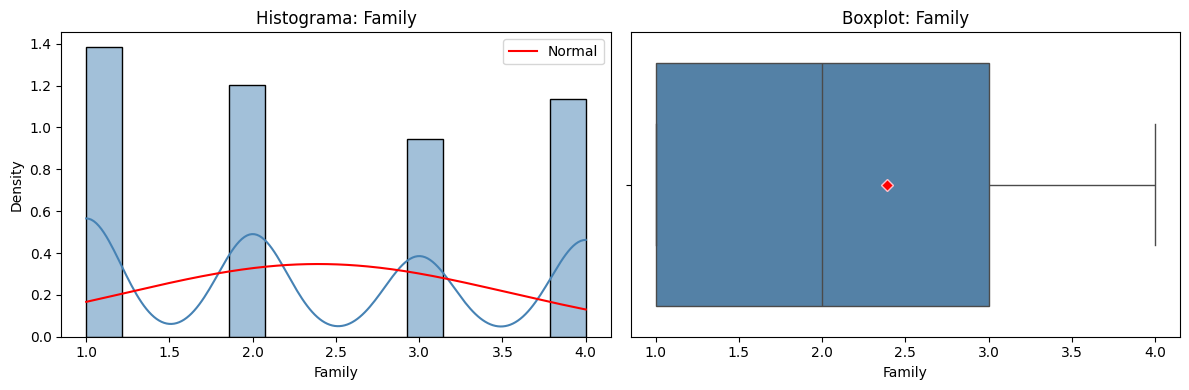

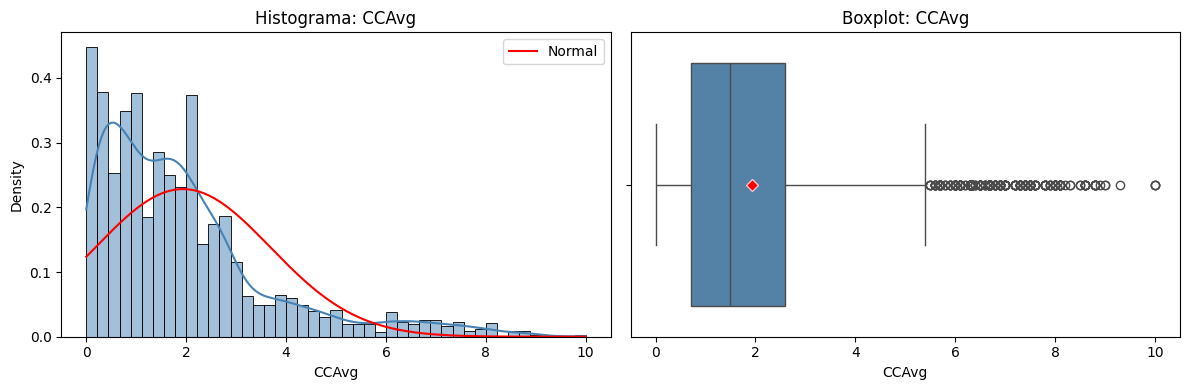

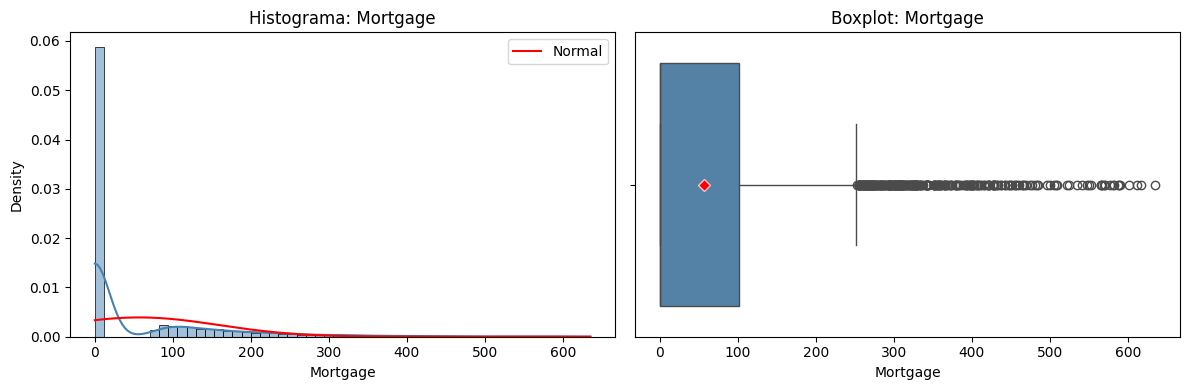

In [12]:
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(loan_df[col], kde=True, stat="density", color="steelblue", ax=ax[0])

    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax[0].plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), color="red", label="Normal")
    ax[0].set_title(f"Histograma: {col}")
    ax[0].legend()

    sns.boxplot(x=loan_df[col], showmeans=True, color="steelblue", ax=ax[1],
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "pink"})
    ax[1].set_title(f"Boxplot: {col}")

    plt.tight_layout()
    plt.show()


**ANálisis de histogramas**

Age: presenta una distribución aproximadamente simétrica (asimetría = −0.023), aunque más plana que la distribución normal, lo que coincide con su curtosis negativa (−1.162).

Income: muestra una cola hacia la derecha, consistente con su asimetría positiva (0.842). Aunque su curtosis es cercana a cero (−0.046), el histograma no presenta una forma normal.

Mortgage: concentra numerosas observaciones en cero y presenta una cola larga hacia valores elevados, consistente con su asimetría positiva (2.104) y curtosis elevada (4.760).

---
**Análisis de boxplots**

Las variables Age y Experience presentan medias y medianas muy cercanas, indicando distribuciones aproximadamente simétricas. En Income, Family, CCAvg y Mortgage, la media supera a la mediana, lo que sugiere asimetría positiva, especialmente pronunciada en Mortgage.

Además, los boxplots muestran posibles valores atípicos elevados en Income, CCAvg y Mortgage. Estos valores no necesariamente son errores, por lo que no se eliminaron únicamente por ser extremos.




8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


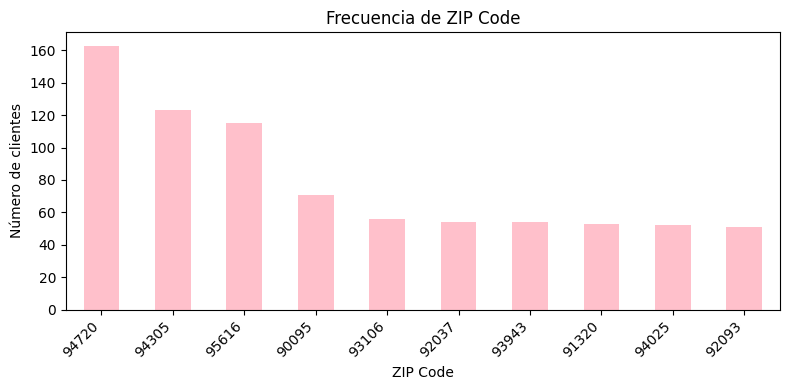

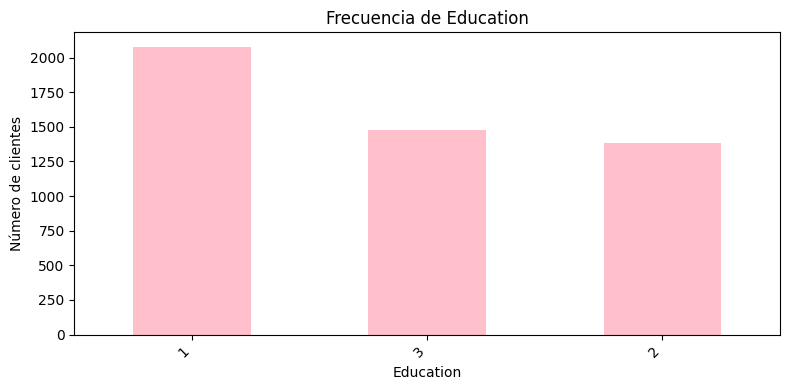

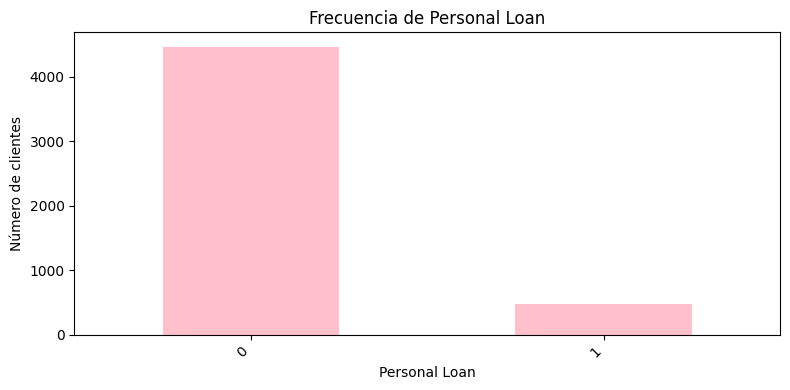

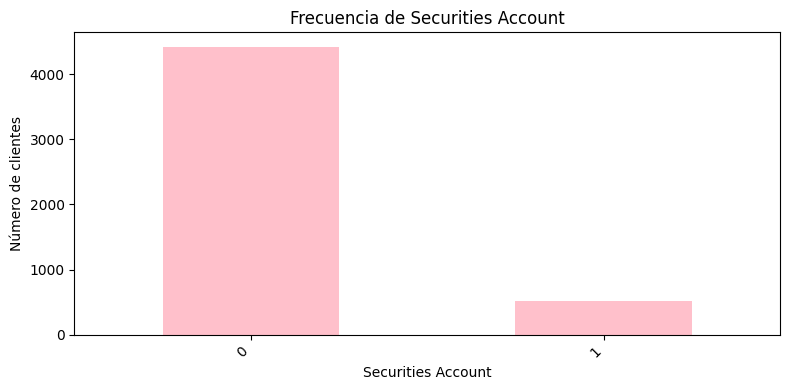

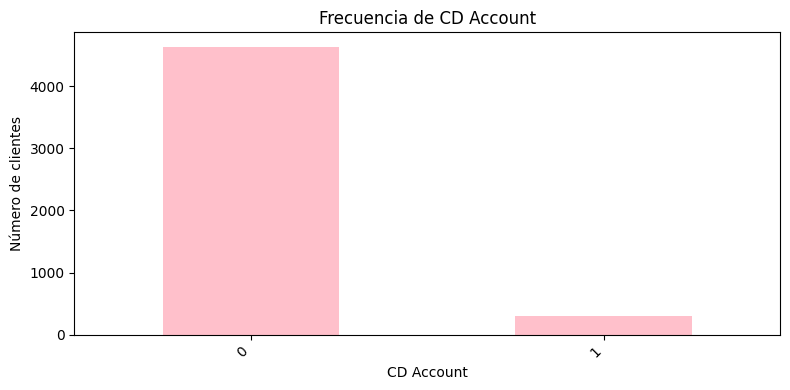

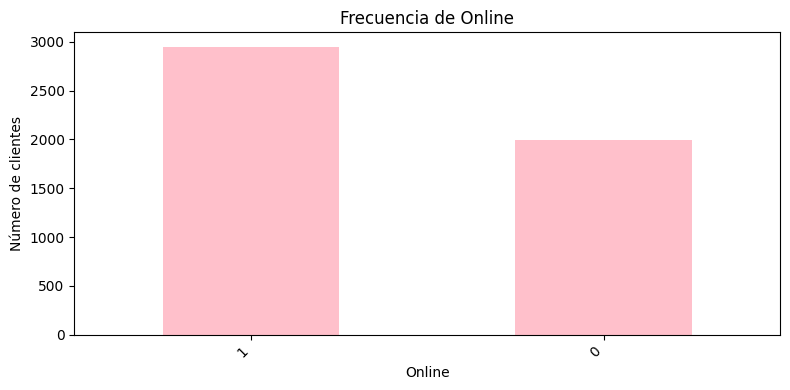

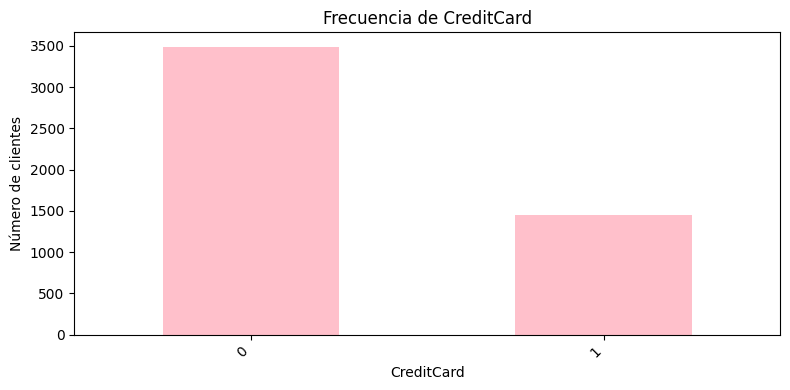

In [14]:
display(loan_df[cat_cols].describe())

for col in cat_cols:
    frecuencias = loan_df[col].value_counts().head(10)

    plt.figure(figsize=(8, 4))
    frecuencias.plot(kind="bar", color="pink")
    plt.title(f"Frecuencia de {col}")
    plt.xlabel(col)
    plt.ylabel("Número de clientes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


Se analizaron las 7 variables categóricas mediante estadísticas descriptivas y gráficos de barras. ZIP Code presentó la mayor cardinalidad, con 467 categorías, por lo que se visualizaron únicamente las 10 más frecuentes.

Se observó que la mayoría de los clientes no aceptó un préstamo personal (4,462 de 4,941). Asímismo, predominan los clientes sin cuentas de valores ni certificados de depósito, mientras que el uso de servicios bancarios en línea es más frecuente.

En cuanto al nivel educativo, la categoría 1 fue la más común con 2,079 clientes.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

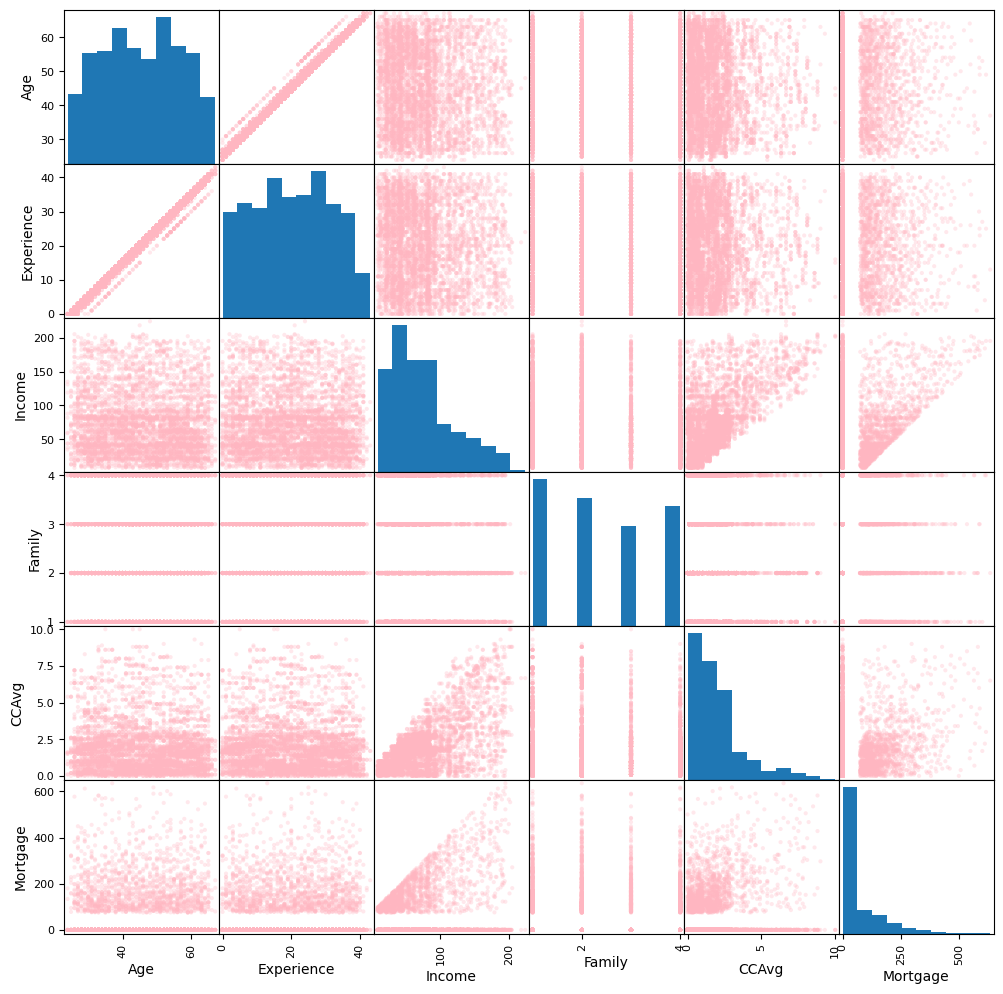

In [15]:
pd.plotting.scatter_matrix(
    loan_df[num_cols],
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.3,
    color="lightpink"
)

plt.show()


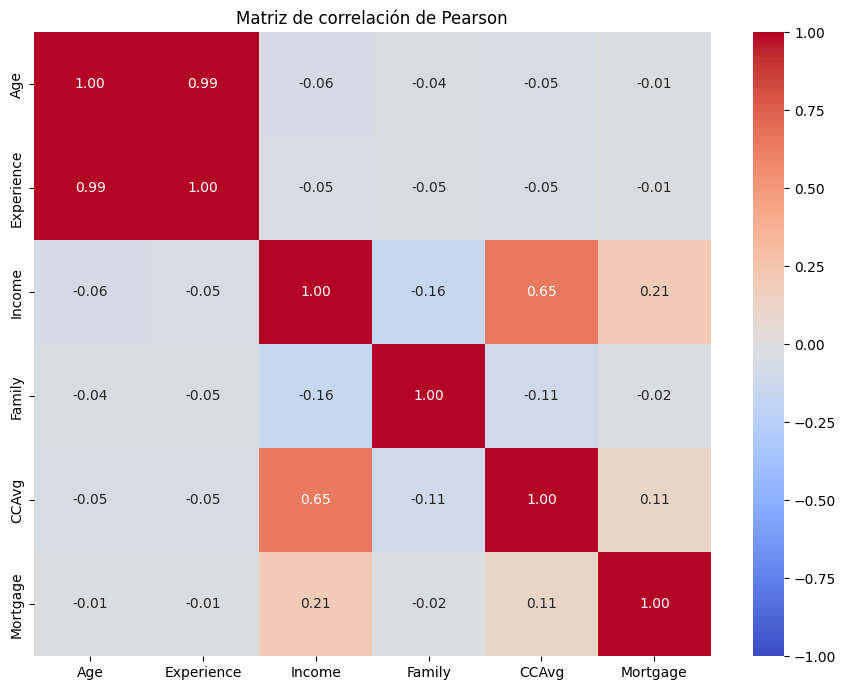

In [16]:
correlacion = loan_df[num_cols].corr(method="pearson")

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)

plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()


Se genera una matriz de dispersión y un mapa de calor de Pearson para analizar las relaciones entre las 6 variables numéricas.

Se seleccionó el par **Income y CCAvg**, cuya gráfica de dispersión muestra una tendencia positiva: los clientes con mayores ingresos anuales tienden a presentar mayores gastos mensuales con tarjeta de crédito.

El coeficiente de Pearson obtenido (r = 0.65) confirma una correlación positiva moderadamente fuerte, consistente con el patrón observado en la gráfica. Sin embargo, esta asociación no implica necesariamente causalidad.

Adicionalmente, Age y Experience presentan una correlación positiva muy fuerte (r = 0.99).

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


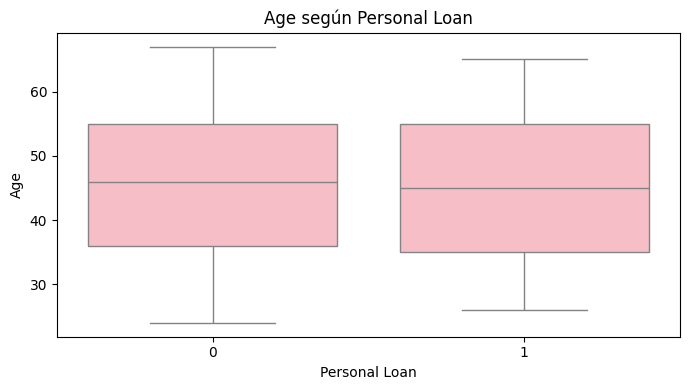

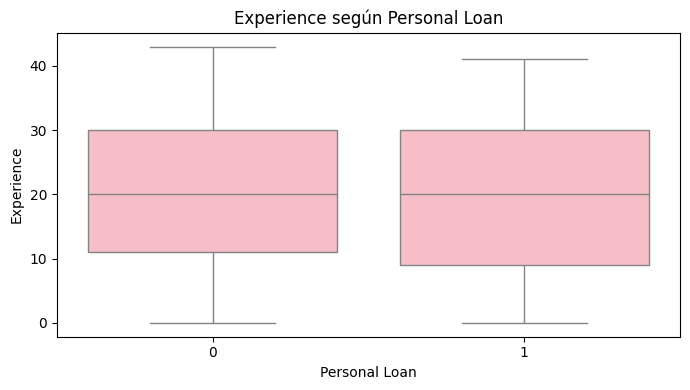

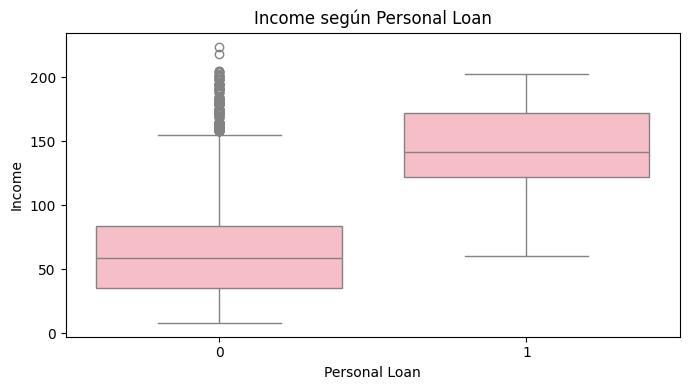

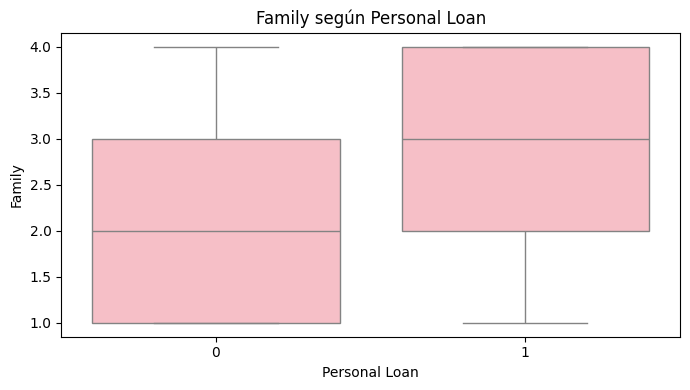

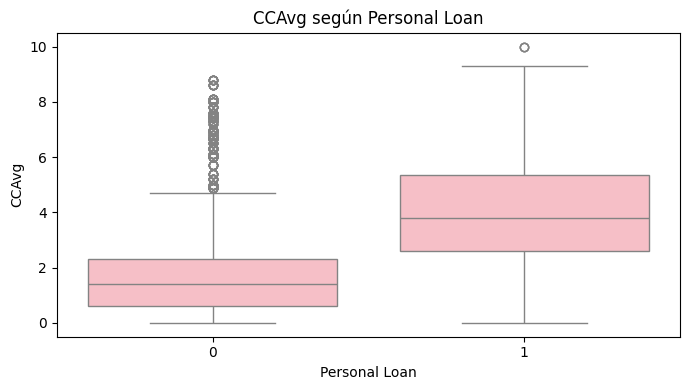

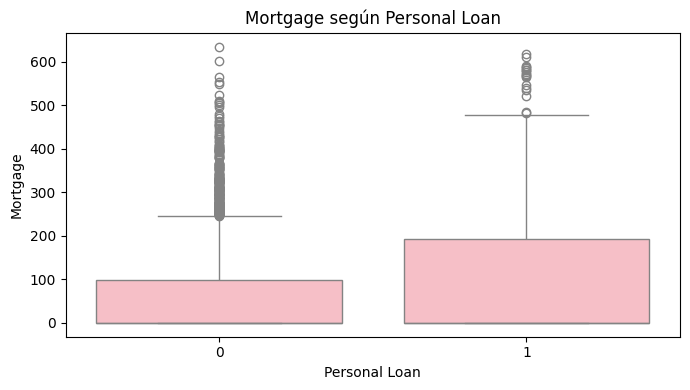

In [17]:
for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=loan_df, x="Personal Loan", y=col, color="lightpink")
    plt.title(f"{col} según Personal Loan")
    plt.tight_layout()
    plt.show()


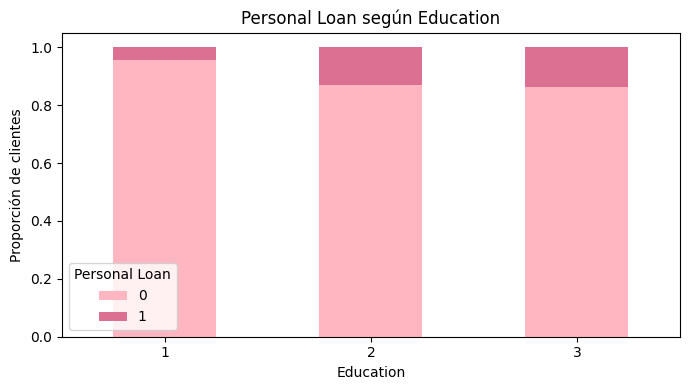

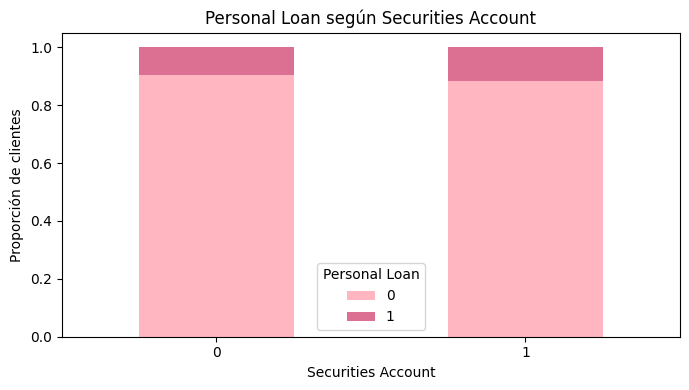

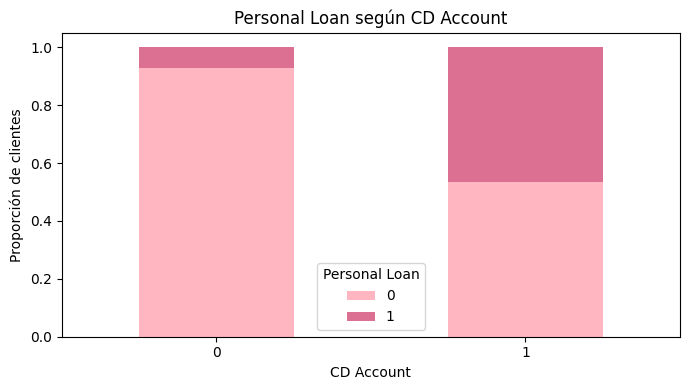

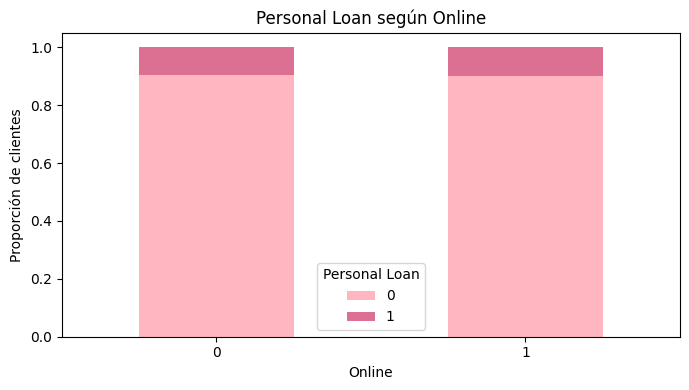

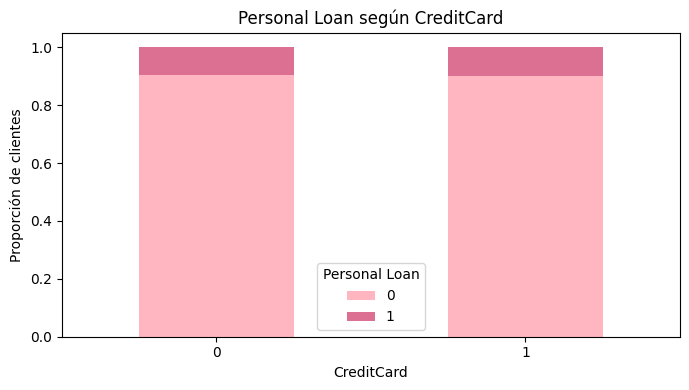

In [18]:

for col in cat_cols:
    if col not in ["ZIP Code", "Personal Loan"]:
        tabla = pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index")

        tabla.plot(kind="bar", stacked=True, figsize=(7, 4),
                   color=["lightpink", "palevioletred"])
        plt.title(f"Personal Loan según {col}")
        plt.xlabel(col)
        plt.ylabel("Proporción de clientes")
        plt.legend(title="Personal Loan")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()


**Análisis de variables numéricas**

Los boxplots muestran que los clientes que aceptaron el préstamo personal presentan mayores ingresos anuales y gastos mensuales con tarjeta de crédito. Las medianas de Income son 142 y 59, mientras que las de CCAvg son 3.8 y 1.4, respectivamente.

También se observa una mediana de Family más alta entre quienes aceptaron el préstamo (3 frente a 2). En cambio, Age y Experience presentan distribuciones similares entre ambos grupos. Mortgage tiene una mediana de cero en ambos casos, aunque muestra mayor dispersión entre quienes aceptaron el préstamo.

---
**Análisis de variables categóricas**

La variable CD Account presenta una diferencia importante: el 46.51 % de los clientes que poseen este producto aceptó el préstamo, frente al 7.31 % de quienes no lo poseen.

Asimismo, los clientes con niveles educativos 2 y 3 muestran proporciones de aceptación superiores a las del nivel 1. Por otro lado, las variables Online y CreditCard presentan diferencias pequeñas entre categorías.

En conjunto, Income, CCAvg y CD Account muestran asociaciones relevantes con la aceptación del préstamo personal. Sin embargo, estas relaciones no implican causalidad.


---


**Declaración de uso de inteligencia artificial**

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje grande]. https://chatgpt.com/



Se usó como herramienta de apoyo para la generación, corrección, y revisión de código en Python.


---